ENGINEERED URL FEATURES


,URL,URL_Length,Num_Dots,Num_Slashes,Num_Question,Num_Equal,Num_Hyphen,Num_At,Num_Percent,Num_Digits,Num_Special,Has_HTTPS,Has_IP,Subdomain_Count,Query_Length,Path_Length,Num_Parameters
0,https://www.google.com,22,2,2,0,0,0,0,0,0,5,1,0,1,0,0,0
1,https://www.microsoft.com,25,2,2,0,0,0,0,0,0,5,1,0,1,0,0,0
2,https://www.github.com,22,2,2,0,0,0,0,0,0,5,1,0,1,0,0,0
3,https://www.wikipedia.org,25,2,2,0,0,0,0,0,0,5,1,0,1,0,0,0
4,https://www.amazon.com,22,2,2,0,0,0,0,0,0,5,1,0,1,0,0,0
5,https://www.apple.com,21,2,2,0,0,0,0,0,0,5,1,0,1,0,0,0
6,https://www.python.org,22,2,2,0,0,0,0,0,0,5,1,0,1,0,0,0
7,https://www.youtube.com,23,2,2,0,0,0,0,0,0,5,1,0,1,0,0,0
8,https://www.linkedin.com,24,2,2,0,0,0,0,0,0,5,1,0,1,0,0,0
9,https://www.facebook.com,24,2,2,0,0,0,0,0,0,5,1,0,1,0,0,0



URL ANOMALY DETECTION RESULTS


,URL,Anomaly_Score,Status
10,http://192.168.1.10/login,-0.007757,Abnormal
15,http://example.com/login.php?id=123456789&sess...,-0.006970,Abnormal
19,http://very-long-domain-name-example.com/accou...,-0.003297,Abnormal
18,http://example.com/download.php?file=abc&user=...,-0.001154,Abnormal
17,http://192.168.10.20:8080/admin/login,0.000288,Normal
11,http://example.com/login?user=admin&password=1234,0.011826,Normal
14,http://example.com/a/b/c/d/e/f/g/h/i/j/k,0.012198,Normal
16,http://example.com/@admin/login,0.058892,Normal
13,http://free-prize-example.com/winner/claim-now,0.107560,Normal
12,http://secure-login-example.com/verify/account,0.113273,Normal



DETECTED ABNORMAL URLs


,URL,Anomaly_Score,Status
10,http://192.168.1.10/login,-0.007757,Abnormal
15,http://example.com/login.php?id=123456789&sess...,-0.006970,Abnormal
19,http://very-long-domain-name-example.com/accou...,-0.003297,Abnormal
18,http://example.com/download.php?file=abc&user=...,-0.001154,Abnormal


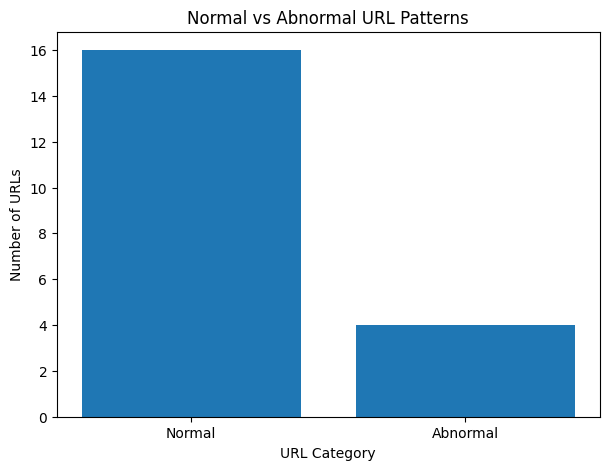

In [1]:
# Experiment 6:  Using a set of URLs, detect abnormal patterns using feature engineering. 
# ============================================================
# URL ABNORMAL PATTERN DETECTION USING FEATURE ENGINEERING
# ============================================================

# Import required libraries
import pandas as pd
import re
import matplotlib.pyplot as plt

from urllib.parse import urlparse
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import IsolationForest


# ------------------------------------------------------------
# 1. Create a set of URLs
# ------------------------------------------------------------
# A separate dataset is not required for this example.
# You can replace these URLs with your own URLs.

urls = [
    "https://www.google.com",
    "https://www.microsoft.com",
    "https://www.github.com",
    "https://www.wikipedia.org",
    "https://www.amazon.com",
    "https://www.apple.com",
    "https://www.python.org",
    "https://www.youtube.com",
    "https://www.linkedin.com",
    "https://www.facebook.com",

    # URLs containing unusual patterns
    "http://192.168.1.10/login",
    "http://example.com/login?user=admin&password=1234",
    "http://secure-login-example.com/verify/account",
    "http://free-prize-example.com/winner/claim-now",
    "http://example.com/a/b/c/d/e/f/g/h/i/j/k",
    "http://example.com/login.php?id=123456789&session=987654321",
    "http://example.com/@admin/login",
    "http://192.168.10.20:8080/admin/login",
    "http://example.com/download.php?file=abc&user=test&id=123",
    "http://very-long-domain-name-example.com/account/verify/login/password"
]


# Convert URLs into a DataFrame
df = pd.DataFrame(urls, columns=["URL"])


# ------------------------------------------------------------
# 2. Feature Engineering
# ------------------------------------------------------------
# Extract numerical characteristics from every URL.

def extract_features(url):

    parsed = urlparse(url)

    hostname = parsed.hostname if parsed.hostname else ""
    path = parsed.path
    query = parsed.query

    # Length of the complete URL
    url_length = len(url)

    # Count different URL characters
    num_dots = url.count(".")
    num_slashes = url.count("/")
    num_question = url.count("?")
    num_equal = url.count("=")
    num_hyphen = url.count("-")
    num_at = url.count("@")
    num_percent = url.count("%")

    # Count digits
    num_digits = sum(c.isdigit() for c in url)

    # Count special characters
    num_special = len(re.findall(r"[^a-zA-Z0-9]", url))

    # Check whether HTTPS is used
    has_https = 1 if parsed.scheme == "https" else 0

    # Check whether the hostname is an IP address
    ip_pattern = r"^(?:\d{1,3}\.){3}\d{1,3}$"
    has_ip = 1 if re.match(ip_pattern, hostname) else 0

    # Count subdomains
    if hostname:
        subdomain_count = max(0, len(hostname.split(".")) - 2)
    else:
        subdomain_count = 0

    # Query and path characteristics
    query_length = len(query)
    path_length = len(path)

    # Number of parameters in the query
    num_parameters = len(query.split("&")) if query else 0

    return [
        url_length,
        num_dots,
        num_slashes,
        num_question,
        num_equal,
        num_hyphen,
        num_at,
        num_percent,
        num_digits,
        num_special,
        has_https,
        has_ip,
        subdomain_count,
        query_length,
        path_length,
        num_parameters
    ]


# Feature names
feature_names = [
    "URL_Length",
    "Num_Dots",
    "Num_Slashes",
    "Num_Question",
    "Num_Equal",
    "Num_Hyphen",
    "Num_At",
    "Num_Percent",
    "Num_Digits",
    "Num_Special",
    "Has_HTTPS",
    "Has_IP",
    "Subdomain_Count",
    "Query_Length",
    "Path_Length",
    "Num_Parameters"
]


# Extract features from all URLs
features = df["URL"].apply(extract_features)

feature_df = pd.DataFrame(
    features.tolist(),
    columns=feature_names
)


# ------------------------------------------------------------
# 3. Display the engineered features
# ------------------------------------------------------------

print("ENGINEERED URL FEATURES")
display(
    pd.concat([df, feature_df], axis=1)
)


# ------------------------------------------------------------
# 4. Feature Scaling
# ------------------------------------------------------------
# StandardScaler puts all numerical features on a similar scale.

scaler = StandardScaler()

X_scaled = scaler.fit_transform(feature_df)


# ------------------------------------------------------------
# 5. Isolation Forest for Anomaly Detection
# ------------------------------------------------------------
# Isolation Forest detects URLs whose patterns differ
# significantly from the majority of URLs.

model = IsolationForest(
    contamination=0.20,
    random_state=42
)

model.fit(X_scaled)


# ------------------------------------------------------------
# 6. Predict Normal and Abnormal URLs
# ------------------------------------------------------------

predictions = model.predict(X_scaled)

result_df = df.copy()

# Isolation Forest returns:
#  1  -> Normal
# -1  -> Abnormal

result_df["Status"] = predictions

result_df["Status"] = result_df["Status"].map({
    1: "Normal",
    -1: "Abnormal"
})


# ------------------------------------------------------------
# 7. Calculate anomaly score
# ------------------------------------------------------------
# Lower scores indicate more unusual URL patterns.

result_df["Anomaly_Score"] = model.decision_function(X_scaled)


# ------------------------------------------------------------
# 8. Display final detection results
# ------------------------------------------------------------

print("\nURL ANOMALY DETECTION RESULTS")

display(
    result_df[
        ["URL", "Anomaly_Score", "Status"]
    ].sort_values("Anomaly_Score")
)


# ------------------------------------------------------------
# 9. Display only abnormal URLs
# ------------------------------------------------------------

print("\nDETECTED ABNORMAL URLs")

abnormal_urls = result_df[
    result_df["Status"] == "Abnormal"
]

display(
    abnormal_urls[
        ["URL", "Anomaly_Score", "Status"]
    ].sort_values("Anomaly_Score")
)


# ------------------------------------------------------------
# 10. Visualize Normal vs Abnormal URLs
# ------------------------------------------------------------

normal_count = (result_df["Status"] == "Normal").sum()
abnormal_count = (result_df["Status"] == "Abnormal").sum()

plt.figure(figsize=(7, 5))

plt.bar(
    ["Normal", "Abnormal"],
    [normal_count, abnormal_count]
)

plt.xlabel("URL Category")
plt.ylabel("Number of URLs")
plt.title("Normal vs Abnormal URL Patterns")

plt.show()